In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
from glob import glob
from scipy.spatial.distance import cdist
import re
from scipy.ndimage import gaussian_filter

In [2]:
def minmax_normalize(img):
    return cv2.normalize(img, None, 0, 1, cv2.NORM_MINMAX,dtype=cv2.CV_32F)

# Question 1

In [3]:
def manual_hough_transform(edge_image, rho_res=1, theta_res=np.pi/180, threshold=100):
    
    height, width = edge_image.shape
    diag_len = int(np.sqrt(height**2 + width**2)) #range of possible distances
    rhos = np.arange(-diag_len, diag_len, rho_res)
    
    thetas = np.arange(0, np.pi, theta_res)
    
    accumulator = np.zeros((len(rhos), len(thetas)), dtype=np.uint64) # Rows : rho, Columns : theta
    
    y_idxs, x_idxs = np.nonzero(edge_image)
    
    cos_t = np.cos(thetas)
    sin_t = np.sin(thetas)
    
    for i in range(len(x_idxs)):
        x = x_idxs[i]
        y = y_idxs[i]
        
        for t_idx in range(len(thetas)):
            rho_val = x * cos_t[t_idx] + y * sin_t[t_idx]
            
            rho_idx = int(round(rho_val + diag_len))
            accumulator[rho_idx, t_idx] += 1
            
    lines = []
    for r in range(accumulator.shape[0]):
        for t in range(accumulator.shape[1]):
            if accumulator[r, t] >= threshold:
                rho = rhos[r]
                theta = thetas[t]
                lines.append((rho, theta))
                
    return lines

In [4]:
def draw_hough_lines(img, lines):
    output = img.copy()
  
    for rho, theta in lines:
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv2.line(output, (x1, y1), (x2, y2), (0, 0, 255), 2)
    return output

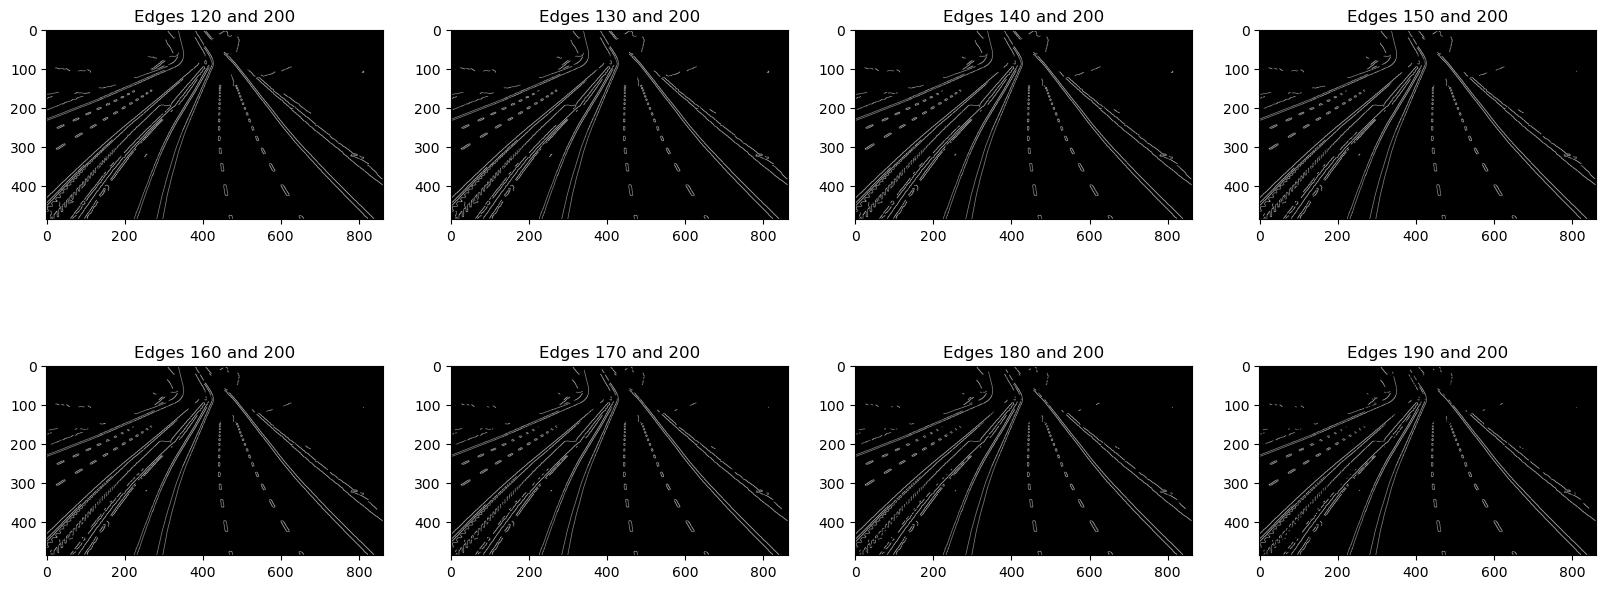

In [5]:
img1 = cv2.imread('./imgs/highway1.jpg')

gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
blur1 = cv2.GaussianBlur(gray1, (7, 7), 0)
plt.figure(figsize=(20,8))

for (i,j) in enumerate(range(12,20)):
    edges2 = cv2.Canny(blur1, j * 10, 200)
    plt.subplot(2,4,i + 1)
    plt.imshow(edges2, cmap='gray') 
    plt.title(f'Edges {j * 10} and 200')

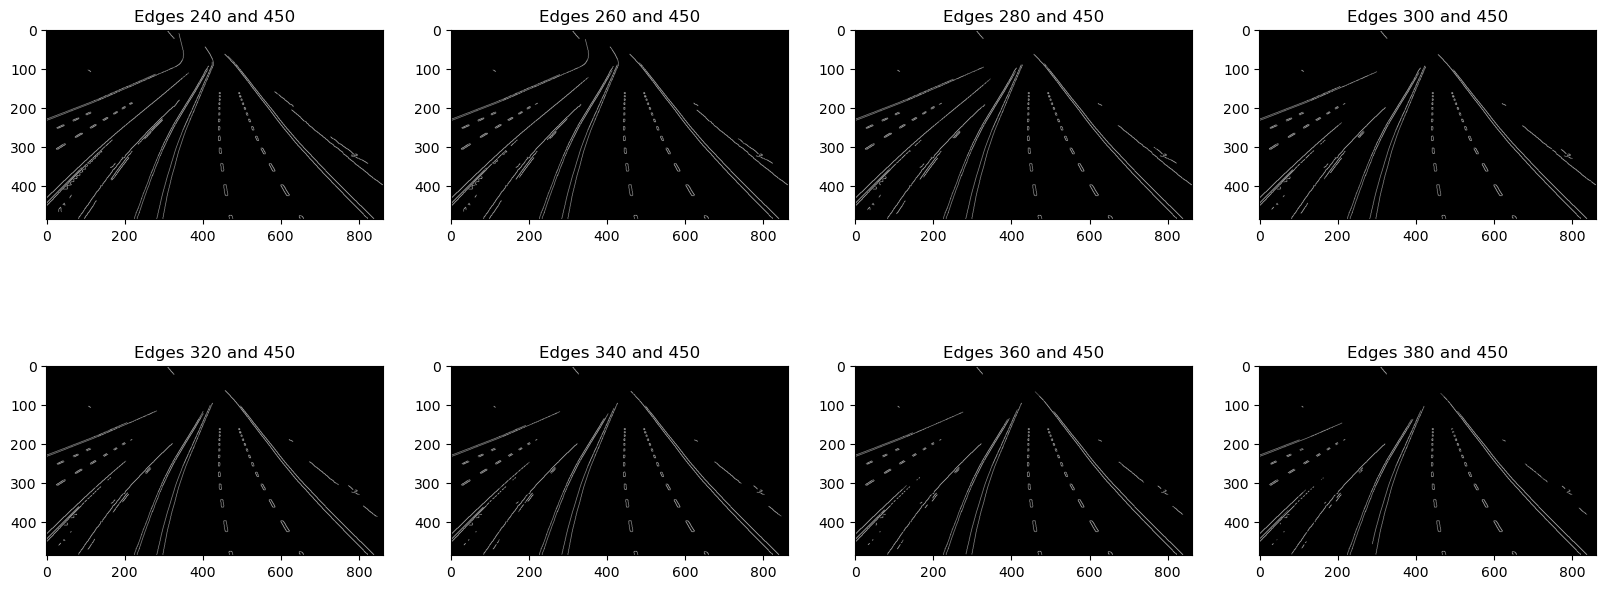

In [6]:
blur1 = cv2.GaussianBlur(gray1, (5, 5), 0)
plt.figure(figsize=(20,8))

for (i,j) in enumerate(range(12,20)):
    edges2 = cv2.Canny(blur1, j * 20, 450)
    plt.subplot(2,4,i + 1)
    plt.imshow(edges2, cmap='gray') 
    plt.title(f'Edges {j * 20} and 450')

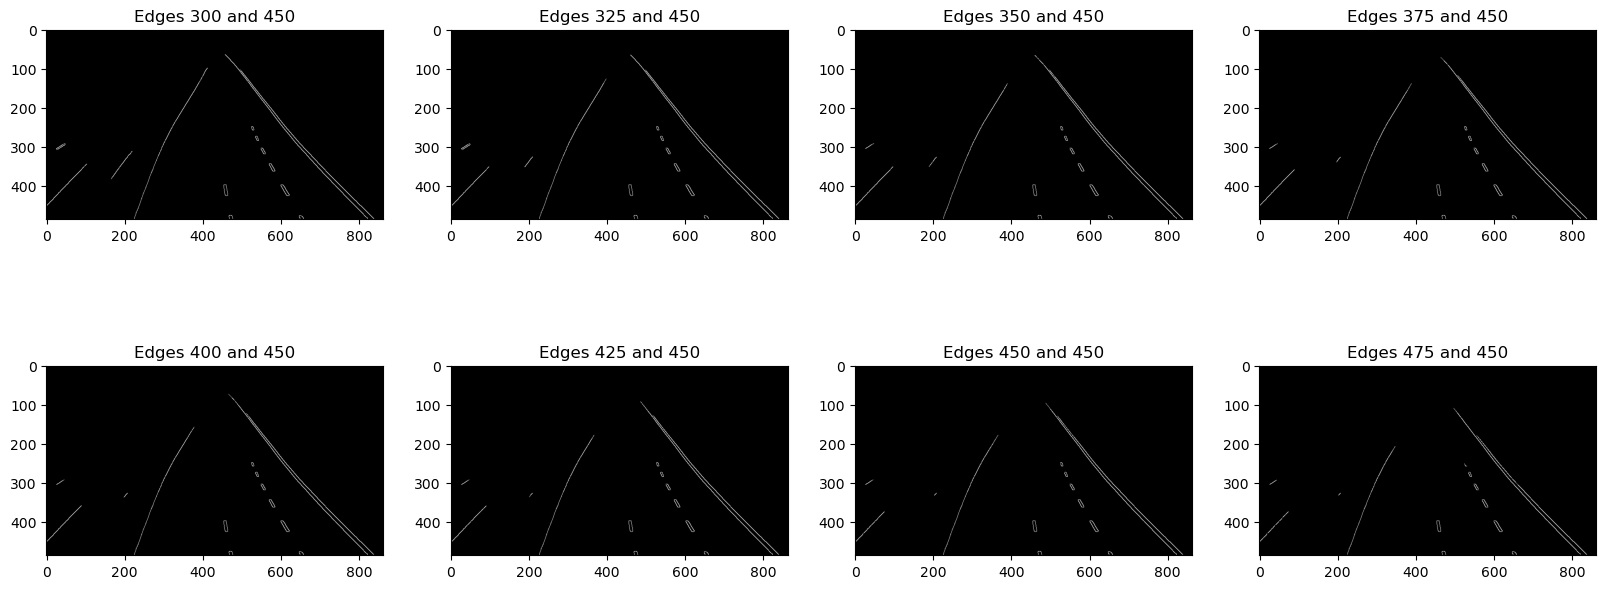

In [7]:
blur1 = cv2.GaussianBlur(gray1, (5, 5), 0)
plt.figure(figsize=(20,8))

for (i,j) in enumerate(range(12,20)):
    edges2 = cv2.Canny(blur1, j * 25, 650)
    plt.subplot(2,4,i + 1)
    plt.imshow(edges2, cmap='gray') 
    plt.title(f'Edges {j * 25} and 450')

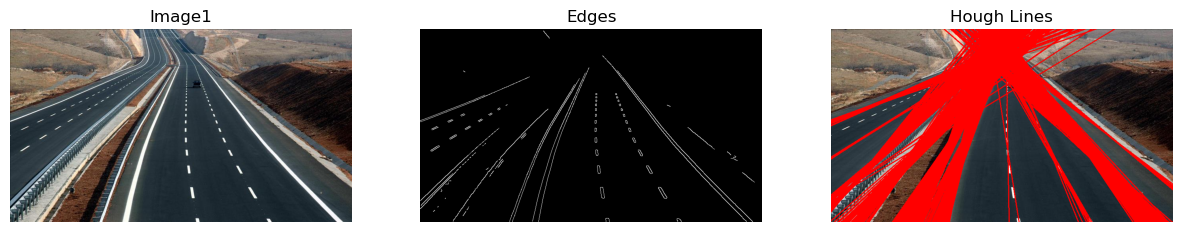

In [8]:
blur1 = cv2.GaussianBlur(gray1, (5, 5), 0)
edges1 = cv2.Canny(blur1, 350, 450)
detected_lines1 = manual_hough_transform(edges1, threshold=48)

result1 = draw_hough_lines(img1, detected_lines1)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)) 
plt.axis('off')
plt.title('Image1')

plt.subplot(1,3,2)
plt.imshow(edges1, cmap='gray') 
plt.axis('off')
plt.title('Edges')

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(result1, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Hough Lines')

plt.show()

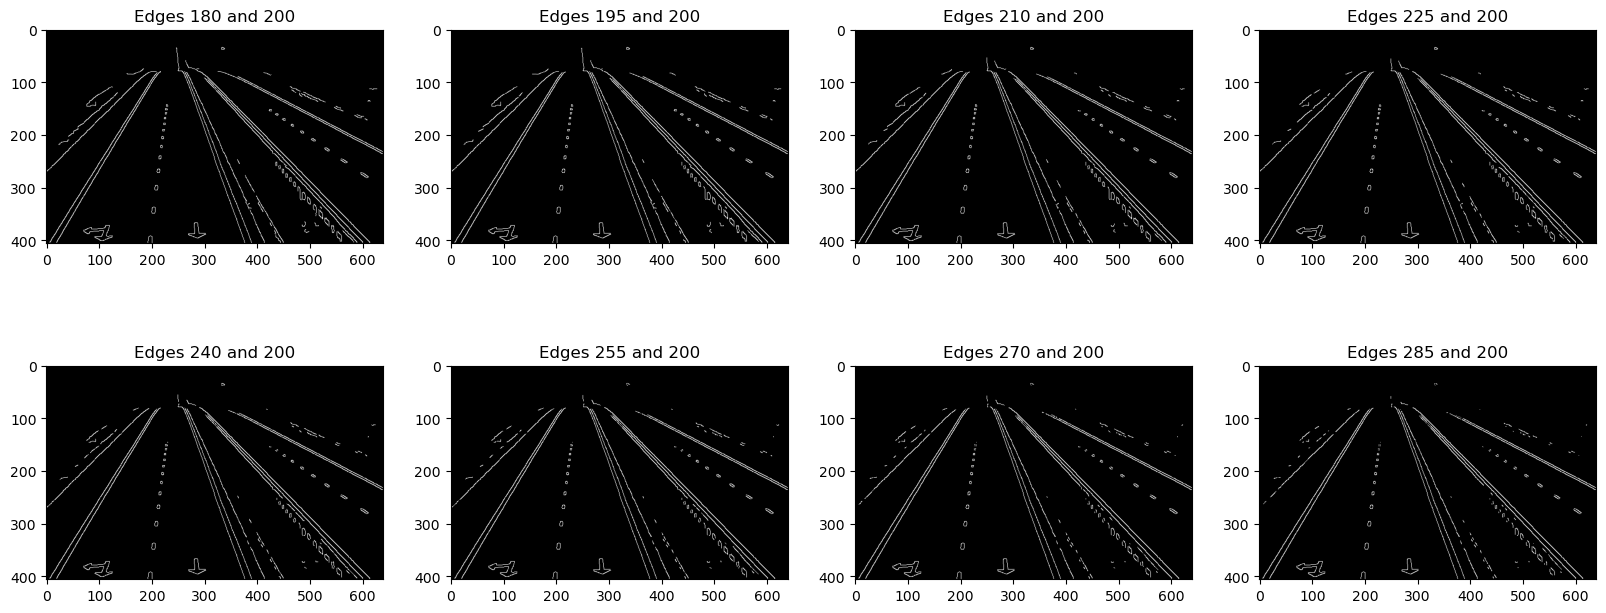

In [9]:
img2 = cv2.imread('./imgs/highway2.jpg')

gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
blur2 = cv2.GaussianBlur(gray2, (5, 5), 0)
plt.figure(figsize=(20,8))

for (i,j) in enumerate(range(12,20)):
    edges2 = cv2.Canny(blur2, j * 15, 300)
    plt.subplot(2,4,i + 1)
    plt.imshow(edges2, cmap='gray') 
    plt.title(f'Edges {j * 15} and 200')

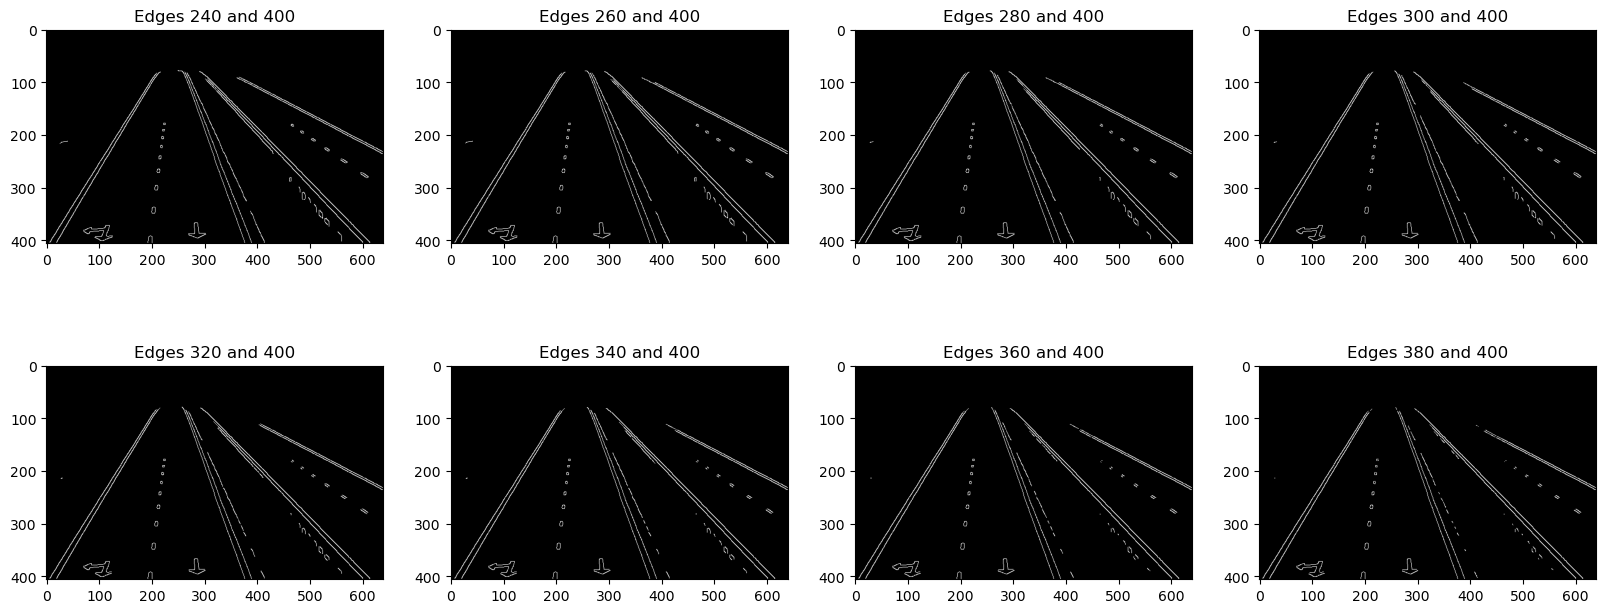

In [10]:
blur2 = cv2.GaussianBlur(gray2, (5, 5), 0)
plt.figure(figsize=(20,8))

for (i,j) in enumerate(range(12,20)):
    edges2 = cv2.Canny(blur2, j * 20, 400)
    plt.subplot(2,4,i + 1)
    plt.imshow(edges2, cmap='gray') 
    plt.title(f'Edges {j * 20} and 400')

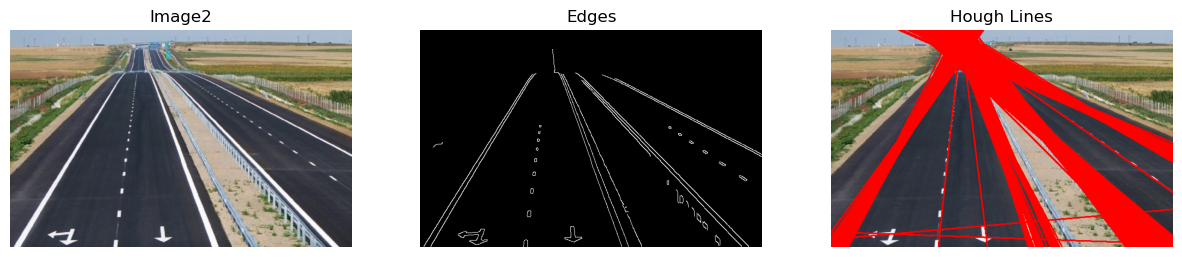

In [11]:
img2 = cv2.imread('./imgs/highway2.jpg')

gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
blur2 = cv2.GaussianBlur(gray2, (5, 5), 0)
edges2 = cv2.Canny(blur2, 200, 400)
detected_lines2 = manual_hough_transform(edges2, threshold=47)

result2 = draw_hough_lines(img2, detected_lines2)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)) 
plt.axis('off')
plt.title('Image2')

plt.subplot(1,3,2)
plt.imshow(edges2, cmap='gray') 
plt.axis('off')
plt.title('Edges')

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(result2, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Hough Lines')

plt.show()

# Question 2

In [12]:
def load_dataset_revised(dataset_path):
    train_data = []
    test_data = []
    
    sift = cv2.SIFT_create()

    image_paths = sorted(glob(os.path.join(dataset_path, 's*_*.jpg')))

    for img_path in image_paths:
        filename = os.path.basename(img_path)

        match = re.match(r's(\d{2})_(\d{2})\.jpg', filename)
        
        if match:
            person_id = int(match.group(1))
            image_number = int(match.group(2))
            
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            
            kp, desc = sift.detectAndCompute(img, None)
            
            data_point = {'label': person_id, 'desc': desc}
            
            if image_number <= 8: 
                train_data.append(data_point)
            else:
                test_data.append(data_point)
                
    return train_data, test_data

In [13]:
def match_descriptors_manual(desc1, desc2, threshold):
    distances = cdist(desc1, desc2, 'euclidean') #distance matrix
    min_dists = np.min(distances, axis=1) #for each descriptor in desc1, find the minimum distance to any descriptor in desc2
    good_matches = np.sum(min_dists < threshold)
    return good_matches

In [14]:
def evaluate_accuracy(train_data, test_data, MATCH_THRESHOLD):
    rank_1_correct = 0
    rank_14_correct = 0
    total_queries = 0
    
    # only the first test image of each person in test set
    test_queries = {}
    for item in test_data:
        if item['label'] not in test_queries:
            test_queries[item['label']] = item
    
    
    for person_id, query in test_queries.items():
        total_queries += 1
        
        scores = []
        
        for train in train_data:
            matches = match_descriptors_manual(query['desc'], train['desc'], threshold=MATCH_THRESHOLD)
            scores.append((matches, train['label']))
        
        scores.sort(key=lambda x: x[0], reverse=True)
        
        predicted_label = scores[0][1]

        print(f'Query: Person {person_id}')

        if predicted_label == person_id:
            rank_1_correct += 1
            print(f'Result: CORRECT. Top Match: Person {predicted_label} ({scores[0][0]} matches)')
        else:
            print(f'Result: INCORRECT. Predicted: Person {predicted_label} ({scores[0][0]} matches). Correct: Person {person_id}')

        top_14 = scores[:14]
        
        top_14_labels = [label for matches, label in top_14]
        if person_id in top_14_labels:
            rank_14_correct += 1

        print(f'Top 14 Matches:')
        for rank, (num_matches, label) in enumerate(top_14):
            is_correct = ' (CORRECT)' if label == person_id else ''
            print(f'  Rank {rank+1}: Person {label} with {num_matches} matches{is_correct}')
        print('--------------------------------------')
        
    if total_queries > 0:
        rank_1_accuracy = rank_1_correct / total_queries * 100
        rank_14_accuracy = rank_14_correct / total_queries * 100
        print('--------------------------------------')
        print(f'Rank-1 Accuracy: {rank_1_correct} / {total_queries} = {rank_1_accuracy:.2f}%')
        print(f'Rank-14 Accuracy: {rank_14_correct} / {total_queries} = {rank_14_accuracy:.2f}%')

In [15]:
train_data, test_data = load_dataset_revised('./imgs/cropped_faces')

In [16]:
thresh = 200
evaluate_accuracy(train_data, test_data, thresh)

Query: Person 1
Result: CORRECT. Top Match: Person 1 (15 matches)
Top 14 Matches:
  Rank 1: Person 1 with 15 matches (CORRECT)
  Rank 2: Person 1 with 11 matches (CORRECT)
  Rank 3: Person 35 with 8 matches
  Rank 4: Person 1 with 5 matches (CORRECT)
  Rank 5: Person 4 with 4 matches
  Rank 6: Person 5 with 4 matches
  Rank 7: Person 23 with 4 matches
  Rank 8: Person 49 with 4 matches
  Rank 9: Person 5 with 3 matches
  Rank 10: Person 10 with 3 matches
  Rank 11: Person 17 with 3 matches
  Rank 12: Person 17 with 3 matches
  Rank 13: Person 28 with 3 matches
  Rank 14: Person 32 with 3 matches
--------------------------------------
Query: Person 2
Result: CORRECT. Top Match: Person 2 (11 matches)
Top 14 Matches:
  Rank 1: Person 2 with 11 matches (CORRECT)
  Rank 2: Person 2 with 10 matches (CORRECT)
  Rank 3: Person 2 with 4 matches (CORRECT)
  Rank 4: Person 2 with 3 matches (CORRECT)
  Rank 5: Person 2 with 3 matches (CORRECT)
  Rank 6: Person 13 with 3 matches
  Rank 7: Person 2 

In [17]:
thresh = 300
evaluate_accuracy(train_data, test_data, thresh)

Query: Person 1
Result: CORRECT. Top Match: Person 1 (44 matches)
Top 14 Matches:
  Rank 1: Person 1 with 44 matches (CORRECT)
  Rank 2: Person 1 with 39 matches (CORRECT)
  Rank 3: Person 1 with 38 matches (CORRECT)
  Rank 4: Person 10 with 37 matches
  Rank 5: Person 41 with 37 matches
  Rank 6: Person 19 with 36 matches
  Rank 7: Person 31 with 36 matches
  Rank 8: Person 17 with 35 matches
  Rank 9: Person 1 with 34 matches (CORRECT)
  Rank 10: Person 35 with 34 matches
  Rank 11: Person 39 with 34 matches
  Rank 12: Person 10 with 33 matches
  Rank 13: Person 17 with 33 matches
  Rank 14: Person 25 with 33 matches
--------------------------------------
Query: Person 2
Result: CORRECT. Top Match: Person 2 (24 matches)
Top 14 Matches:
  Rank 1: Person 2 with 24 matches (CORRECT)
  Rank 2: Person 2 with 23 matches (CORRECT)
  Rank 3: Person 31 with 21 matches
  Rank 4: Person 8 with 19 matches
  Rank 5: Person 8 with 19 matches
  Rank 6: Person 2 with 18 matches (CORRECT)
  Rank 7: P

# Question 3

In [18]:
def harris(gray_img, window_size=3, k=0.04, threshold_percent=0.01):
    Ix = np.gradient(gray_img, axis=1)
    Iy = np.gradient(gray_img, axis=0)
    
    Ix2 = Ix * Ix
    Iy2 = Iy * Iy
    Ixy = Ix * Iy
    
    sigma = window_size / 6.0
    
    A = gaussian_filter(Ix2, sigma=sigma)
    B = gaussian_filter(Iy2, sigma=sigma)
    C = gaussian_filter(Ixy, sigma=sigma)
    
    det_M = A * B - C * C
    trace_M = A + B
    
    R = det_M - k * (trace_M ** 2)
    threshold = threshold_percent * R.max() #find corners above a percentage of the maximum response
    corner_locs = np.argwhere(R > threshold)
    keypoints = [cv2.KeyPoint(float(x), float(y), size=3) for y, x in corner_locs] #needed for SIFT's compute function
    return keypoints

In [19]:
def sift_features(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    keypoints = harris(gray, window_size=5, k=0.04, threshold_percent=0.01)
    sift = cv2.SIFT_create()
    kp, des = sift.compute(gray, keypoints)
    return kp, des

In [20]:
def compute_homography(pts1, pts2):
    A = []
    for i in range(len(pts1)):
        x, y = pts1[i][0], pts1[i][1]
        u, v = pts2[i][0], pts2[i][1]
        
        A.append([-x, -y, -1, 0, 0, 0, x*u, y*u, u])
        A.append([0, 0, 0, -x, -y, -1, x*v, y*v, v])
        
    A = np.array(A)
    U, S, Vh = np.linalg.svd(A) #find H (null space of A)
    H = Vh[-1, :].reshape(3, 3)

    H = H / H[2, 2]
    return H

In [21]:
def ransac_homography(pts1, pts2, num_iter=1000, threshold=5.0):
    best_H = None
    max_inliers = 0
    
    n_points = len(pts1)
    if n_points < 4: #minimum points
        return None
        
    pts1_h = np.hstack((pts1, np.ones((n_points, 1))))
    
    for _ in range(num_iter):
        indices = np.random.choice(n_points, 4, replace=False)
        src_sample = pts1[indices]
        dst_sample = pts2[indices]
    
        H = compute_homography(src_sample, dst_sample)
        projected = pts1_h @ H.T
        epsilon = 1e-10
        projected = projected / (projected[:, 2:3] + epsilon)
        
        dists = np.linalg.norm(pts2 - projected[:, :2], axis=1)
        
        inliers_count = np.sum(dists < threshold)
        
        if inliers_count > max_inliers:
            max_inliers = inliers_count
            best_H = H
            
    return best_H

In [22]:
def match(des1, des2, threshold=200):
    matches = []
    dists = cdist(des1, des2, 'euclidean')
    
    for i in range(len(dists)):
        best_idx = np.argmin(dists[i])
        min_dist = dists[i][best_idx]
        if min_dist < threshold:
            matches.append([i, best_idx])
    return np.array(matches)

In [23]:
def panorama_stitching(img1, img2):
    kp1, des1 = sift_features(img1)
    kp2, des2 = sift_features(img2)
    
    matches = match(des1, des2, threshold=150)
    
    if len(matches) > 4:
        pts1 = np.float32([kp1[m[0]].pt for m in matches])
        pts2 = np.float32([kp2[m[1]].pt for m in matches])

        H = ransac_homography(pts2, pts1, num_iter=1000, threshold=5.0)
        
        if H is not None:
            print('Best Homography Matrix:\n', H)
            
            h1, w1 = img1.shape[:2]
            h2, w2 = img2.shape[:2]
            
            corners = np.float32([[0, 0], [w2, 0], [0, h2], [w2, h2]]).reshape(-1, 1, 2)
            warped_corners = cv2.perspectiveTransform(corners, H)
            
            x_min, y_min = np.min(warped_corners, axis=(0, 1)).astype(int)
            x_max, y_max = np.max(warped_corners, axis=(0, 1)).astype(int)

            offset_x = max(0, -x_min)
            offset_y = max(0, -y_min)
            
            canvas_width = x_max - x_min + offset_x + w1
            canvas_height = y_max - y_min + offset_y + h1
            
            T = np.array([[1, 0, offset_x], [0, 1, offset_y], [0, 0, 1]], dtype=np.float32)
            H_final = T @ H

            warped_img2 = cv2.warpPerspective(img2, H_final, (canvas_width, canvas_height))
            warped_img2[offset_y:h1 + offset_y, offset_x:w1 + offset_x] = img1
            
            plt.figure(figsize=(12,6))
            plt.title('Panorama')
            plt.imshow(cv2.cvtColor(warped_img2, cv2.COLOR_BGR2RGB))
            plt.show()

Best Homography Matrix:
 [[ 7.51112331e-01  2.48442374e-02  4.45887154e+02]
 [-1.40242044e-01  8.91472620e-01  8.01712068e+01]
 [-2.25131653e-04 -5.19857285e-05  1.00000000e+00]]


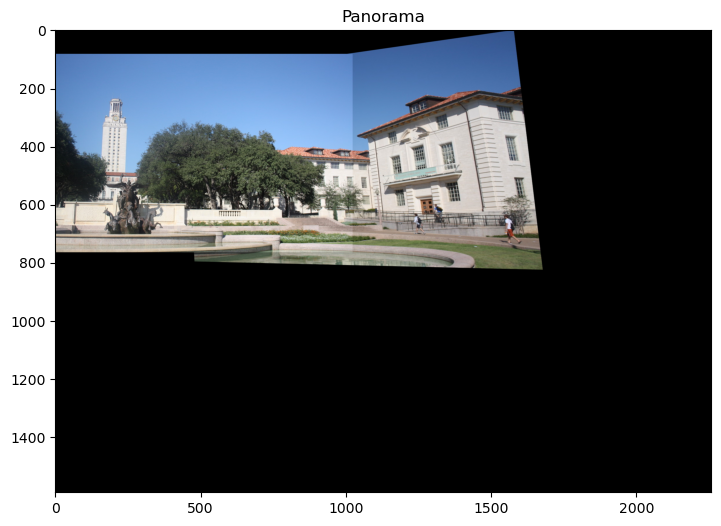

In [24]:
img1 = cv2.imread('./imgs/uttower_left.jpg')
img2 = cv2.imread('./imgs/uttower_right.jpg')
panorama_stitching(img1, img2)